# Parcial 1 - Sistemas Inteligentes II

**Estudiante:** Lina María Nieto Alarcón 

**Profesor:** Jorge Alberto Jaramillo Garzón

---


In [1]:
import sys
print(sys.executable)

# Instalar scikit-learn en el mismo Python que usa este notebook
!{sys.executable} -m pip install scikit-learn

C:\Users\linaN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\linaN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
%pip install matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: C:\Users\linaN\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Ejercicio #1

**Implemente validacion cruzada k-fold ( sin librerias) y evalue en la base de datos Iris el resultado de clasificar 
las clases versicolor vs virginica con todas las caracter ́ısticas. Entrene y compare un clasificador Naive Bayes con
distribucion gaussiana y un clasificador por minimos cuadrados con regularizacion tipo ridge (λ). En cada fold:
estandarice usando solo el conjunto de entrenamiento y reporte: accuracy, matriz de confusion promedio y varianza entre folds. Pruebe k ∈ {2, 5, 10} y discuta el balance entre varianza y costo computacional.**

## Paso 1. Preparación del entorno

En este paso se verifica el intérprete de Python utilizado por el notebook y se instalan las librerías necesarias para ejecutar el análisis.

### ¿Qué se utiliza?

- **sys**: permite identificar el intérprete de Python activo.
- **scikit-learn**: proporciona el conjunto de datos Iris y la función para construir la matriz de confusión.
- **matplotlib**: permite configurar y generar visualizaciones.
- **NumPy**: permite trabajar con arreglos, operaciones matemáticas y cálculos estadísticos.

Las librerías se cargan antes de comenzar para que las funciones y clases utilizadas en los pasos siguientes estén disponibles.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Cargar el dataset Iris y la métrica para construir matrices de confusión.
from sklearn.datasets import load_iris
from sklearn.metrics import confusion_matrix

# Configurar un estilo y tamaños consistentes para las gráficas.
plt.style.use("seaborn-v0_8")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 10

print("Librerías cargadas")

Librerías cargadas


## Paso 2. Carga y selección de los datos

Se utiliza la base de datos Iris, que contiene mediciones de flores y una etiqueta de clase para cada muestra. Cada registro tiene cuatro características: longitud y ancho del sépalo, y longitud y ancho del pétalo.

In [4]:
iris = load_iris()
# Cada fila representa una flor y las cuatro columnas son sus características.
datos_total = iris.data
# Las etiquetas originales son: 0=setosa, 1=versicolor y 2=virginica.
etiquetas_total = iris.target
nombres_clases_total = iris.target_names

print("Clases originales:", nombres_clases_total)
print("Forma de datos_total:", datos_total.shape)

# Crear una máscara booleana para conservar solo versicolor y virginica.
mascara = (etiquetas_total == 1) | (etiquetas_total == 2)
datos = datos_total[mascara] # Se agregan los datos correspondientes a las clases 1 y 2.
etiquetas = etiquetas_total[mascara] # Se agregan las etiquetas correspondientes a las clases 1 y 2.

print("\nEjercicio 1:")
print("  datos :", datos.shape)
print("  etiquetas :", etiquetas.shape)
print("  etiquetas :", np.unique(etiquetas))

# El ejercicio 2 utiliza las tres clases originales del dataset.


Clases originales: ['setosa' 'versicolor' 'virginica']
Forma de datos_total: (150, 4)

Ejercicio 1:
  datos : (100, 4)
  etiquetas : (100,)
  etiquetas : [1 2]


## Paso 3. Funciones auxiliares y métricas

Antes de entrenar los clasificadores se preparan algunas operaciones comunes del análisis.

### Estandarización

La estandarización permite que las características trabajen en escalas comparables. Para cada valor se resta la media y se divide entre la desviación estándar:

$$
z = \frac{x-\mu}{\sigma}
$$

La media y la desviación estándar se calculan con el conjunto de entrenamiento y luego se aplican al conjunto de prueba. Esto evita utilizar información del conjunto de prueba durante el entrenamiento.

### Matriz de confusión

La matriz de confusión permite comparar las etiquetas reales con las etiquetas predichas. Sus filas representan las clases reales y sus columnas representan las clases predichas.

Para dos clases, se puede representar de forma general así:

$$
\begin{bmatrix}
\text{VP} & \text{FP} \\
\text{FN} & \text{VN}
\end{bmatrix}
$$

In [5]:
from typing import Tuple

def estandarizar_datos_entrenamiento(X: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Calcula media y desviación estándar por característica (columna) y
    devuelve X estandarizado. Se usa SOLO con el train, porque estos
    parámetros son los que luego se reutilizan sobre el test.

    Ej: X=[[1,10],[2,20],[3,30]] -> media=[2,20], desv≈[0.82,8.16]
    """
    # La media y la desviación se calculan únicamente con entrenamiento.
    media = X.mean(axis=0) # media por columna, forma (n_características,)
    desviacion_estandar = X.std(axis=0)
    # Evitar división entre cero si alguna característica es constante.
    desviacion_estandar[desviacion_estandar == 0] = 1.0
    X_estandarizado = (X - media) / desviacion_estandar
    return X_estandarizado, media, desviacion_estandar


def calcular_matriz_confusion_numpy(etiquetas_reales: np.ndarray, etiquetas_predichas: np.ndarray, etiquetas=None) -> np.ndarray:
    """Construye la matriz de confusión manteniendo un orden fijo de etiquetas."""
    if etiquetas is None:
        # Incluir las etiquetas reales y predichas evita perder alguna clase.
        etiquetas = np.unique(np.concatenate([etiquetas_reales, etiquetas_predichas]))
    etiquetas = np.array(etiquetas)
    matriz_confusion = confusion_matrix(etiquetas_reales, etiquetas_predichas, labels=etiquetas)
    return matriz_confusion, etiquetas


## Paso 4. Clasificador Naive Bayes Gaussiano

**Naive Bayes Gaussiano (clasificador generativo)**  
Usamos el teorema de Bayes para la clase $c_i$ dado el vector de características $\boldsymbol{x}$:
$$ p(c_i \mid \boldsymbol{x}) = \frac{p(\boldsymbol{x} \mid c_i) \, p(c_i)}{p(\boldsymbol{x})} $$
El denominador $p(\boldsymbol{x})$ es igual para todas las clases, así que para clasificar solo necesitamos el numerador. Modelamos la verosimilitud $p(\boldsymbol{x} \mid c_i)$ con una densidad gaussiana (por clase y por característica, asumiendo independencia “naive”):
$$ p(\boldsymbol{x} \mid c_i) \propto \prod_{j} \frac{1}{\sqrt{2\pi\sigma_{i,j}^2}} \exp\left(-\frac{(x_j - \mu_{i,j})^2}{2\sigma_{i,j}^2}\right) $$
En entrenamiento calculamos para cada clase: prior $p(c_i)$ (proporción de muestras), medias $\mu_{i,j}$ y varianzas $\sigma_{i,j}^2$. En predicción trabajamos en log-verosimilitud para evitar underflow y elegimos la clase con mayor score.


In [6]:
class ClasificadorBayesGaussiano:
    """Naive Bayes con distribución gaussiana por característica y clase."""

    def __init__(self):
        # Estos atributos se calculan durante el entrenamiento.
        self.clases_ = None
        self.probabilidades_priori_ = None
        self.medias_ = None
        self.varianzas_ = None

    def ajustar(self, X: np.ndarray, y: np.ndarray):
        """
        Estima media, varianza y prior por clase (uno por característica).
        Ej: X=[[1,2],[1.1,2.1],[5,6]], y=[0,0,1]
            -> clase 0: media≈[1.05,2.05], clase 1: media=[5,6]
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        n_muestras, n_caracteristicas = X.shape

        # Guardar las clases permite conservar sus etiquetas originales.
        self.clases_ = np.unique(y)
        n_clases = len(self.clases_)

        self.medias_ = np.zeros((n_clases, n_caracteristicas))
        self.varianzas_ = np.zeros((n_clases, n_caracteristicas))
        self.probabilidades_priori_ = np.zeros(n_clases)

        for indice_clase, clase in enumerate(self.clases_):
            # Seleccionar las muestras de una clase para estimar sus parámetros.
            X_clase = X[y == clase]
            self.medias_[indice_clase, :] = X_clase.mean(axis=0)
            # El término pequeño evita varianzas exactamente iguales a cero.
            self.varianzas_[indice_clase, :] = X_clase.var(axis=0)
            self.probabilidades_priori_[indice_clase] = X_clase.shape[0] / n_muestras

    def _log_verosimilitud_gaussiana(self, indice_clase: int, X: np.ndarray) -> np.ndarray:
        """log p(X | clase) sumando log-densidades gaussianas de cada característica."""
        media = self.medias_[indice_clase]
        varianza = self.varianzas_[indice_clase]

        # Trabajar con logaritmos mejora la estabilidad numérica del cálculo.
        ## Aqui se calcula la primera parte de la log-verosimilitud, es por eso que el valor 
        # -0.5 se multiplica por la suma de los logaritmos de 2πσ², 
        # donde σ² es la varianza de cada característica para la clase dada. 
        # Esto representa la normalización de la distribución gaussiana.
        log_probabilidad = -0.5 * np.sum(np.log(2.0 * np.pi * varianza)) # forma: ()
        # aqui el valor 0.5 representa la segunda parte de la log-verosimilitud, 
        # que es la penalización por la distancia de cada muestra a la media, 
        # normalizada por la varianza.
        log_probabilidad -= 0.5 * np.sum(((X - media) ** 2) / varianza, axis=1) # forma: (n_muestras,)
        return log_probabilidad

    def predecir(self, X: np.ndarray) -> np.ndarray:
        """
        Asigna cada muestra a la clase con mayor log-posterior (prior + verosimilitud).
        Ej: si log_posteriores[i] = [-5.2, -3.1] -> predicción = clases_[1]
        """
        X = np.asarray(X, dtype=float)
        n_muestras = X.shape[0]
        n_clases = len(self.clases_)

        log_posteriores = np.zeros((n_muestras, n_clases))

        for indice_clase, clase in enumerate(self.clases_):
            # La probabilidad posterior combina prior y verosimilitud.
            log_prior = np.log(self.probabilidades_priori_[indice_clase])
            log_verosimilitud = self._log_verosimilitud_gaussiana(indice_clase, X)
            log_posteriores[:, indice_clase] = log_prior + log_verosimilitud

        # Elegir el índice de la clase con el mayor log-posterior.
        indices_clase = np.argmax(log_posteriores, axis=1)
        return self.clases_[indices_clase]

## Paso 5. Clasificador por mínimos cuadrados Ridge

En esta etapa se construye un clasificador lineal regularizado. Como el problema tiene dos clases, las etiquetas se transforman temporalmente a -1 y 1.

Ridge calcula los pesos del modelo combinando mínimos cuadrados con una penalización controlada por lambda:

$$
\mathbf{w}=(\mathbf{X}^{T}\mathbf{X}+\lambda\mathbf{I})^{-1}\mathbf{X}^{T}\mathbf{y}
$$

### Pasos

1. Se transforman las clases a valores numéricos.
2. Se calculan los pesos del modelo.
3. Se obtiene un puntaje para cada muestra.
4. El signo del puntaje determina la clase predicha.

Se utilizan álgebra matricial, regularización Ridge y np.linalg.solve para resolver el sistema.

In [7]:
class ClasificadorRidge:
    """Clasificador geométrico por mínimos cuadrados con regularización ridge."""

    def __init__(self, lambda_regularizacion: float = 1.0):
        # Lambda controla cuánto se penalizan pesos grandes.
        self.lambda_regularizacion = lambda_regularizacion
        self.pesos_ = None
        self.clases_ = None

    def ajustar(self, X: np.ndarray, y: np.ndarray):
        """
        Resuelve w = (XᵀX + λI)⁻¹Xᵀy con y remapeado a {-1,+1}.
        Ej: clases_=[1,2] -> clase 2 se mapea a +1, clase 1 a -1.
        """
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        n_muestras, n_caracteristicas = X.shape

        self.clases_ = np.unique(y)
        if len(self.clases_) != 2:
            raise ValueError("ClasificadorRidge solo implementado para problemas binarios")

        # Convertir las dos clases a los valores numéricos -1 y 1.
        clase_positiva = self.clases_[1]
        y_mapeado = np.where(y == clase_positiva, 1.0, -1.0)

        # Añadir una columna de unos para aprender el término independiente.
        X_con_bias = np.hstack([X, np.ones((n_muestras, 1))])
        dimension = X_con_bias.shape[1]

        # Resolver la ecuación de ridge sin invertir explícitamente la matriz.
        matriz_sistema = X_con_bias.T @ X_con_bias + self.lambda_regularizacion * np.eye(dimension)
        vector_independiente = X_con_bias.T @ y_mapeado
        self.pesos_ = np.linalg.solve(matriz_sistema, vector_independiente)

    def predecir(self, X: np.ndarray) -> np.ndarray:
        """Puntaje lineal Xw; signo >=0 -> clase positiva, si no -> clase negativa."""
        X = np.asarray(X, dtype=float)
        n_muestras = X.shape[0]
        # Añadir una columna de unos para el término independiente.
        # Esto hace que la matriz de características tenga una columna adicional que representa 
        # el sesgo (bias) o término independiente en el modelo lineal. 
        # Al concatenar una columna de unos, se permite que el modelo aprenda un intercepto además
        # de los pesos para las características originales.
        X_con_bias = np.hstack([X, np.ones((n_muestras, 1))]) 

        # El signo del puntaje determina la clase predicha.
        puntajes = X_con_bias @ self.pesos_ # puntajes es igual a Xw, donde w son los pesos aprendidos
        y_mapeado_predicho = np.where(puntajes >= 0.0, 1.0, -1.0)

        # Recuperar las etiquetas originales de Iris.
        y_predicha = np.where(y_mapeado_predicho == 1.0, self.clases_[1], self.clases_[0])
        return y_predicha

## Paso 6. Organización de las métricas

Este bloque reúne las operaciones que permiten preparar los datos y evaluar las predicciones de manera uniforme.

El accuracy representa la proporción de predicciones correctas sobre el total de muestras. La matriz de confusión organiza las comparaciones entre etiquetas reales y predichas, permitiendo observar los aciertos y errores de cada clase.

Estas métricas se aplican durante cada fold para que Naive Bayes y Ridge sean evaluados bajo las mismas condiciones.

In [8]:
# Utilidades: estandarización y métricas básicas
def calcular_accuracy(etiquetas_reales: np.ndarray, etiquetas_predichas: np.ndarray) -> float:
    """Calcula la proporción de predicciones correctas."""
    return np.mean(etiquetas_reales == etiquetas_predichas)


def calcular_matriz_confusion(etiquetas_reales: np.ndarray, etiquetas_predichas: np.ndarray, etiquetas=None) -> np.ndarray:
    """Construye la matriz de confusión conservando el orden de las etiquetas."""
    if etiquetas is None:
        etiquetas = np.unique(np.concatenate([etiquetas_reales, etiquetas_predichas]))
    etiquetas = np.array(etiquetas)
    matriz_confusion = confusion_matrix(etiquetas_reales, etiquetas_predichas, labels=etiquetas)
    return matriz_confusion, etiquetas


## Paso 7. Validación cruzada k-fold

La validación cruzada permite evaluar el comportamiento de un modelo usando diferentes divisiones de los datos.

En cada repetición se utiliza un fold para prueba y los demás para entrenamiento. El rendimiento general se resume promediando el resultado de los folds:

$$
\text{rendimiento promedio}=\frac{1}{k}\sum_{r=1}^{k}\text{accuracy}_r
$$

### Procedimiento

1. Se mezclan los índices de las muestras usando una semilla fija.
2. Se dividen los datos en varios pliegues.
3. Se entrena y evalúa un modelo en cada fold.
4. Se calculan el accuracy, la varianza y la matriz de confusión promedio.

Se utilizan `k = 2`, `k = 5` y `k = 10`, junto con la semilla `42`, para comparar configuraciones reproducibles.

In [9]:
# Implementación manual de validación cruzada k-fold

def generar_particiones_kfold(n_muestras: int, k: int, semilla: int = 42):
    """Genera índices de entrenamiento y prueba para validación cruzada k-fold.
    Devuelve una lista de tuplas (train_indices, test_indices) para cada fold.
    """
    # Usar una semilla fija hace reproducible la división de los datos.
    rng = np.random.RandomState(semilla)
    # Se mezclan los índices de las muestras para que cada fold sea representativo.
    indices = np.arange(n_muestras)
    # Mezclar los índices asegura que los pliegues sean aleatorios y representativos de
    # la distribución de datos.
    rng.shuffle(indices)

    # Repartir las muestras en pliegues de tamaños lo más equilibrados posible.
    tamanos_pliegues = np.full(k, n_muestras // k, dtype=int)
    tamanos_pliegues[: n_muestras % k] += 1

    pliegues = []
    inicio = 0
    # Crear los pliegues según los tamaños calculados.
    for tamano_pliegue in tamanos_pliegues:
        fin = inicio + tamano_pliegue
        pliegues.append(indices[inicio:fin])
        inicio = fin

    particiones = []
    # Crear las particiones para cada fold.
    for indice_pliegue in range(k):
        # Un pliegue se reserva para prueba y los restantes para entrenamiento.
        conjunto_prueba = pliegues[indice_pliegue]
        conjunto_entrenamiento = np.concatenate([
            pliegues[j] for j in range(k) if j != indice_pliegue
        ])
        particiones.append((conjunto_entrenamiento, conjunto_prueba))
    return particiones


def validar_modelo_kfold(X: np.ndarray,
                         y: np.ndarray,
                         clase_modelo,
                         k: int,
                         estandarizar: bool = True,
                         semilla: int = 42,
                         verbose: bool = True,
                         **kwargs_modelo):
    """Realiza validación cruzada k-fold para un modelo dado."""
    X = np.asarray(X)
    y = np.asarray(y)
    n_muestras = X.shape[0]

    particiones = generar_particiones_kfold(n_muestras, k, semilla=semilla)

    precisiones_por_fold = []
    matrices_confusion = []
    # Mantener las mismas etiquetas permite promediar matrices correctamente.
    etiquetas_globales = np.unique(y)
    # Iterar sobre cada fold, entrenar y evaluar el modelo.
    for numero_fold, (indx_entrenamiento, indx_prueba) in enumerate(particiones):
        X_entrenamiento, y_entrenamiento = X[indx_entrenamiento], y[indx_entrenamiento]
        X_prueba, y_prueba = X[indx_prueba], y[indx_prueba]

        if estandarizar:
            # Ajustar la transformación con entrenamiento y aplicarla a prueba.
            X_entrenamiento_std, media, desviacion = estandarizar_datos_entrenamiento(X_entrenamiento)
            X_prueba_std = (X_prueba - media) / desviacion
        else:
            X_entrenamiento_std, X_prueba_std = X_entrenamiento, X_prueba

        # Crear, entrenar y evaluar un modelo independiente en cada fold.
        modelo = clase_modelo(**kwargs_modelo)
        modelo.ajustar(X_entrenamiento_std, y_entrenamiento)
        y_predicha = modelo.predecir(X_prueba_std)

        # Calcular directamente la proporción de predicciones correctas.
        precision_fold = np.mean(y_prueba == y_predicha)
        matriz_confusion, _ = calcular_matriz_confusion_numpy(y_prueba, y_predicha, etiquetas=etiquetas_globales)

        precisiones_por_fold.append(precision_fold)
        matrices_confusion.append(matriz_confusion)

        if verbose:
            print(f"Fold {numero_fold+1}/{k} - accuracy = {precision_fold:.4f}")

    precisiones_por_fold = np.array(precisiones_por_fold)
    matrices_confusion = np.array(matrices_confusion)

    # Resumir el rendimiento y su variabilidad entre los folds.
    precision_promedio = precisiones_por_fold.mean()
    varianza_precision = precisiones_por_fold.var(ddof=1) if len(precisiones_por_fold) > 1 else 0.0
    matriz_confusion_promedio = matrices_confusion.mean(axis=0)

    return {
        "accuracies": precisiones_por_fold,
        "mean_accuracy": precision_promedio,
        "var_accuracy": varianza_precision,
        "mean_confusion_matrix": matriz_confusion_promedio,
        "labels": etiquetas_globales,
    }


## Paso 8. Comparación de los clasificadores

En este paso se organiza la ejecución de los dos modelos y se comparan sus resultados para cada valor de `k`.

Usar las mismas particiones permite comparar los modelos de forma justa, ya que ambos reciben los mismos conjuntos de entrenamiento y prueba.

In [10]:
# Ejecutar y organizar la comparación de los dos clasificadores.
# parametros que ingrensan: X, y, k, semilla
# donde X son los datos, y son las etiquetas, 
# k es el número de folds y semilla es la semilla para la aleatoriedad.
def ejecutar_comparacion(X, y, k, semilla=42):
    """Entrena ambos modelos con los mismos folds y devuelve sus resultados."""
    resultado_bayes = validar_modelo_kfold(
        X,
        y,
        ClasificadorBayesGaussiano,
        k=k,
        estandarizar=True,
        semilla=semilla,
        verbose=False,
    )

    print("Míns. cuadrados Ridge con λ=1.0:")
    resultado_ridge = validar_modelo_kfold(
        X,
        y,
        ClasificadorRidge,
        k=k,
        estandarizar=True,
        semilla=semilla,
        lambda_regularizacion=1.0,
        verbose=False,
    )

    return resultado_bayes, resultado_ridge


def mostrar_resultados_modelos(resultado_bayes, resultado_ridge, k):
    """Muestra accuracy por fold y el resumen de ambos clasificadores."""
    # Comparar los dos modelos fold por fold facilita observar su variabilidad.
    for indice_fold, (accuracy_bayes, accuracy_ridge) in enumerate(
        zip(resultado_bayes["accuracies"], resultado_ridge["accuracies"]),
        start=1,
    ):
        print(
            f"Fold {indice_fold}/{k} - "
            f"NBG acc = {accuracy_bayes:.4f} | "
            f"Ridge acc = {accuracy_ridge:.4f}"
        )

    # Imprimir el promedio, la varianza y la matriz de confusión de cada modelo.
    print()
    print(
        f"Naive Bayes Gaussiano:    "
        f"Acc promedio = {resultado_bayes['mean_accuracy']:.4f}, "
        f"Varianza = {resultado_bayes['var_accuracy']:.6f}"
    )
    print("Matriz de confusión promedio:")
    print(resultado_bayes["mean_confusion_matrix"])

    print()
    print(
        f"Míns. cuadrados Ridge: "
        f"Acc promedio = {resultado_ridge['mean_accuracy']:.4f}, "
        f"Varianza = {resultado_ridge['var_accuracy']:.6f}"
    )
    print("Matriz de confusión promedio:")
    print(resultado_ridge["mean_confusion_matrix"])


## Paso 9. Interpretación de los resultados

Los resultados permiten comparar el desempeño de Naive Bayes Gaussiano y Ridge en diferentes configuraciones de validación cruzada.

### Elementos que se deben observar

- **Accuracy promedio:** indica el rendimiento general del clasificador.
- **Varianza:** muestra qué tan estable es el accuracy entre los distintos folds.
- **Matriz de confusión promedio:** permite identificar qué clases se clasifican correctamente y cuáles se confunden.
- **Valor de `k`:** cambia la cantidad de datos utilizada para entrenar y probar en cada repetición.

En general, se busca un accuracy promedio alto y una varianza baja. Esto significa que el modelo obtiene buenos resultados y mantiene un comportamiento estable en las diferentes divisiones de los datos.

In [11]:
# Comparar Naive Bayes Gaussiano y Ridge para varios valores de k.
valores_k = [2, 5, 10]

# Diccionarios para conservar los resultados de cada modelo y cada valor de k.
resultados_bayes = {}
resultados_ridge = {}

print(" Validación cruzada en Iris (versicolor vs virginica)")

for k in valores_k:
    print(f"\n----------- k = {k} folds--------------\n")

    resultado_bayes, resultado_ridge = ejecutar_comparacion(datos, etiquetas, k)
    resultados_bayes[k] = resultado_bayes
    resultados_ridge[k] = resultado_ridge

    mostrar_resultados_modelos(resultado_bayes, resultado_ridge, k)

 Validación cruzada en Iris (versicolor vs virginica)

----------- k = 2 folds--------------

Míns. cuadrados Ridge con λ=1.0:
Fold 1/2 - NBG acc = 0.9400 | Ridge acc = 0.9600
Fold 2/2 - NBG acc = 0.9400 | Ridge acc = 1.0000

Naive Bayes Gaussiano:    Acc promedio = 0.9400, Varianza = 0.000000
Matriz de confusión promedio:
[[23.5  1.5]
 [ 1.5 23.5]]

Míns. cuadrados Ridge: Acc promedio = 0.9800, Varianza = 0.000800
Matriz de confusión promedio:
[[24.  1.]
 [ 0. 25.]]

----------- k = 5 folds--------------

Míns. cuadrados Ridge con λ=1.0:
Fold 1/5 - NBG acc = 0.9500 | Ridge acc = 0.8000
Fold 2/5 - NBG acc = 0.9500 | Ridge acc = 1.0000
Fold 3/5 - NBG acc = 0.9500 | Ridge acc = 1.0000
Fold 4/5 - NBG acc = 0.9500 | Ridge acc = 1.0000
Fold 5/5 - NBG acc = 0.8500 | Ridge acc = 1.0000

Naive Bayes Gaussiano:    Acc promedio = 0.9300, Varianza = 0.002000
Matriz de confusión promedio:
[[9.4 0.6]
 [0.8 9.2]]

Míns. cuadrados Ridge: Acc promedio = 0.9600, Varianza = 0.008000
Matriz de confusión 

## Comentarios

Al comparar los resultados, Ridge obtiene el mejor rendimiento promedio en todas las configuraciones evaluadas. Para k = 2, alcanza un accuracy de 0.9800, mientras que Naive Bayes obtiene 0.9400. Con k = 5, los valores son 0.9600 para Ridge y 0.9300 para Naive Bayes. Finalmente, con k = 10, Ridge obtiene 0.9700 y Naive Bayes 0.9300.

Las matrices de confusión promedio muestran que ambos clasificadores reconocen correctamente la mayoría de las muestras de versicolor y virginica. Por ejemplo, con k = 10, Ridge presenta valores aproximados de 4.8 y 4.9 en la diagonal, mientras que Naive Bayes presenta 4.7 y 4.6. Esto indica que los dos modelos tienen pocos errores, aunque Ridge logra una separación ligeramente mejor en este conjunto de datos.

La estabilidad cambia según el número de folds. Naive Bayes presenta varianzas de 0.000000, 0.002000 y 0.004556 para k = 2, k = 5 y k = 10, respectivamente. En Ridge, las varianzas son 0.000800, 0.008000 y 0.002333. El resultado más variable aparece en Ridge con k = 5, mientras que con k = 10 mejora su estabilidad y obtiene también un accuracy alto.

Respecto al costo computacional, con k = 2 cada modelo se entrena dos veces, por lo que la ejecución es más rápida. Con k = 5 y k = 10, los modelos se entrenan más veces y el tiempo de cálculo aumenta, pero la evaluación utiliza más particiones y permite observar mejor el comportamiento de los clasificadores.

En este caso, k = 5 puede considerarse una alternativa intermedia entre tiempo de ejecución y cantidad de información obtenida. Sin embargo, k = 10 proporciona el resultado más favorable para Ridge, ya que combina un accuracy de 0.9700 con una varianza de 0.002333. En general, la elección de k depende del equilibrio entre precisión, estabilidad y recursos disponibles.

## Ejercicio 2. Clasificador K-NN y bootstrapping

**Implemente el clasificador K-NN sobre la base de datos Iris (usando las cuatro caracter ́ısticas y las tres clases)
e investigue su desempeno mediante el metodo de bootstrapping a medida que se aumenta el numero de vecinos empleado. Concluya al respecto, senalando ademas que valores de k producen sobreajuste y que valores producen  subajuste, justificando con ejemplos de sus graficas.**

En este ejercicio utilizamos la base de datos Iris completa, es decir, las cuatro características y las tres clases: setosa, versicolor y virginica.

### Fundamento teórico

K-NN clasifica una nueva muestra buscando las muestras de entrenamiento más cercanas. La cercanía se calcula con la distancia euclídea:

$$
d(\mathbf{x},\mathbf{x_i}) = \sqrt{\sum_{j=1}^{p}(x_j-x_{ij})^2}
$$

Después se seleccionan los **k** vecinos más cercanos y la predicción corresponde a la clase que aparece con mayor frecuencia entre ellos.

El valor de **k** influye en el comportamiento del modelo:

- Un **k** muy pequeño hace que el modelo sea sensible a casos individuales y puede producir sobreajuste.
- Un **k** muy grande suaviza demasiado las diferencias entre muestras y puede producir subajuste.
- Un valor intermedio busca un equilibrio entre sensibilidad y generalización.

### Bootstrapping

El bootstrapping crea varias muestras de entrenamiento seleccionando datos con reemplazo. En cada iteración se entrena K-NN con una muestra bootstrap y se evalúa con los datos que no fueron seleccionados, llamados datos OOB (*out-of-bag*).

De esta manera se obtienen varios valores de accuracy para cada cantidad de vecinos. Luego se calcula el promedio y la desviación estándar para observar el rendimiento y su variabilidad.

In [12]:
class ClasificadorKNN:
    """Clasificador K-NN con distancia euclídea y voto mayoritario."""

    def __init__(self, numero_vecinos=5):
        self.numero_vecinos = numero_vecinos
        self.datos_entrenamiento = None
        self.etiquetas_entrenamiento = None

    def ajustar(self, datos, etiquetas):
        """Guarda los datos que se utilizarán como referencia."""
        self.datos_entrenamiento = np.asarray(datos)
        self.etiquetas_entrenamiento = np.asarray(etiquetas)

    def _predecir_una_muestra(self, muestra):
        # Calcular la distancia desde la muestra hasta todos los datos conocidos.
        diferencias = self.datos_entrenamiento - muestra
        distancias = np.sqrt(np.sum(diferencias ** 2, axis=1))
        indices_vecinos = np.argsort(distancias)[:self.numero_vecinos]
        etiquetas_vecinas = self.etiquetas_entrenamiento[indices_vecinos]

        # La clase más repetida entre los vecinos es la predicción.
        clases, cantidades = np.unique(etiquetas_vecinas, return_counts=True)
        return clases[np.argmax(cantidades)]

    def predecir(self, datos):
        """Predice la clase de cada muestra."""
        return np.array([self._predecir_una_muestra(muestra) for muestra in datos])


def evaluar_knn_con_bootstrap(datos, etiquetas, numero_vecinos,
                              numero_iteraciones=200, semilla=42):
    """Calcula accuracies OOB para un valor fijo de vecinos."""
    datos = np.asarray(datos)
    etiquetas = np.asarray(etiquetas)
    numero_muestras = len(datos)
    generador_aleatorio = np.random.RandomState(semilla)
    accuracies = []

    for _ in range(numero_iteraciones):
        # Crear una muestra bootstrap seleccionando índices con reemplazo.
        indices_bootstrap = generador_aleatorio.randint(
            0, numero_muestras, size=numero_muestras
        )

        # Los índices no seleccionados forman el conjunto OOB de evaluación.
        mascara_oob = np.ones(numero_muestras, dtype=bool)
        mascara_oob[indices_bootstrap] = False
        indices_oob = np.where(mascara_oob)[0]
        if len(indices_oob) == 0:
            continue

        modelo = ClasificadorKNN(numero_vecinos)
        modelo.ajustar(datos[indices_bootstrap], etiquetas[indices_bootstrap])
        predicciones = modelo.predecir(datos[indices_oob])
        accuracies.append(calcular_accuracy(etiquetas[indices_oob], predicciones))

    return np.array(accuracies)


Bootstrapping con 200 iteraciones por valor de k

K = 1
Accuracy media = 0.9567
Desviación estándar = 0.0210
Iteraciones válidas = 200
--------------------------------
K = 2
Accuracy media = 0.9488
Desviación estándar = 0.0255
Iteraciones válidas = 200
--------------------------------
K = 3
Accuracy media = 0.9554
Desviación estándar = 0.0219
Iteraciones válidas = 200
--------------------------------
K = 4
Accuracy media = 0.9521
Desviación estándar = 0.0253
Iteraciones válidas = 200
--------------------------------
K = 5
Accuracy media = 0.9582
Desviación estándar = 0.0233
Iteraciones válidas = 200
--------------------------------
K = 6
Accuracy media = 0.9555
Desviación estándar = 0.0257
Iteraciones válidas = 200
--------------------------------
K = 7
Accuracy media = 0.9601
Desviación estándar = 0.0251
Iteraciones válidas = 200
--------------------------------
K = 8
Accuracy media = 0.9582
Desviación estándar = 0.0262
Iteraciones válidas = 200
--------------------------------
K = 9


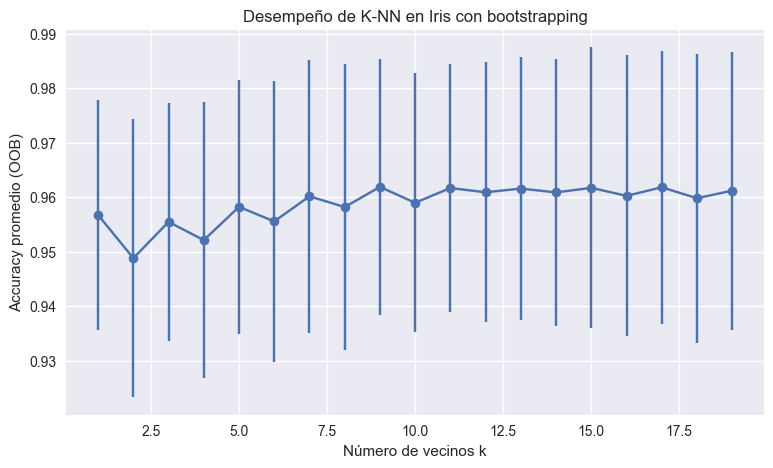

In [13]:
# Evaluar K-NN con bootstrapping para distintos números de vecinos.
valores_vecinos = range(1, 20) # Números de vecinos a evaluar
numero_iteraciones = 200
accuracies_promedio = []
desviaciones_accuracy = []

print(f"Bootstrapping con {numero_iteraciones} iteraciones por valor de k\n")

for numero_vecinos in valores_vecinos:
    accuracies = evaluar_knn_con_bootstrap(
        datos_total,
        etiquetas_total,
        numero_vecinos,
        numero_iteraciones,
        semilla=42,
    )

    promedio = accuracies.mean()
    desviacion = accuracies.std()
    accuracies_promedio.append(promedio)
    desviaciones_accuracy.append(desviacion)

    print(f"K = {numero_vecinos}")
    print(f"Accuracy media = {promedio:.4f}")
    print(f"Desviación estándar = {desviacion:.4f}")
    print(f"Iteraciones válidas = {len(accuracies)}")
    print("-" * 32)

accuracies_promedio = np.array(accuracies_promedio)
desviaciones_accuracy = np.array(desviaciones_accuracy)

# Mostrar el promedio y la variabilidad de cada valor de k.
plt.figure()
plt.errorbar(
    list(valores_vecinos),
    accuracies_promedio,
    yerr=desviaciones_accuracy,
    fmt="-o",
    capsize=3,
)
plt.xlabel("Número de vecinos k")
plt.ylabel("Accuracy promedio (OOB)")
plt.title("Desempeño de K-NN en Iris con bootstrapping")
plt.grid(True)
plt.show()


## Discusión final del ejercicio 2

Los resultados muestran que el accuracy promedio cambia según la cantidad de vecinos utilizada. El valor más alto se obtiene con k = 9, con un accuracy promedio de 0.9619. También se observan resultados altos con k = 11 (0.9616), k = 13 (0.9615) y k = 14 (0.9608).

Cuando k = 1, el modelo obtiene un accuracy promedio de 0.9567, pero cada predicción depende de un solo vecino. Por esta razón, es un valor más sensible a muestras particulares y puede asociarse con un posible sobreajuste. En la gráfica, esta situación se relaciona con la variabilidad del resultado y con la poca capacidad de generalizar cuando una muestra aislada influye demasiado.

Para valores pequeños como k = 2 y k = 4, los accuracies promedio bajan a 0.9488 y 0.9521, respectivamente. Esto muestra que utilizar pocos vecinos no necesariamente produce el mejor resultado en este experimento.

A medida que k aumenta, el accuracy mejora de manera general y alcanza su mejor comportamiento alrededor de k = 9. Sin embargo, utilizar un número excesivamente grande de vecinos puede producir subajuste, porque el modelo podría considerar demasiadas muestras y perder las diferencias entre las clases. En el rango probado hasta k = 14 no se observa un subajuste fuerte, ya que el accuracy se mantiene cercano a 0.96; para confirmarlo completamente sería necesario probar valores de k más grandes.

El bootstrapping se realizó con 200 iteraciones por cada valor de k, y todas las configuraciones tuvieron 200 iteraciones válidas. La desviación estándar estuvo entre 0.0210 y 0.0262, lo que indica una variación moderada entre las muestras OOB.

En conclusión, para este conjunto de datos el valor recomendado es aproximadamente k = 9, porque obtuvo el mayor accuracy promedio. Los valores muy pequeños pueden ser más sensibles y presentar sobreajuste, mientras que valores demasiado grandes podrían generar subajuste. La elección final debe buscar un equilibrio entre accuracy, variabilidad y capacidad de generalización.

## Ejercicio #3

**Compare y contraste los tres clasificadores vistos en clase (geometrico, bayesiano y K-NN) seg un los siguientes criterios: ¿Que suposiciones hace cada uno de los modelos? ¿Cuales son sus requerimientos de entrenamiento en terminos de tiempo de computo y memoria? ¿Como cambiara el desempeño de cada uno cuando se aumenta el numero de dimensiones del espacio de caracter ́ısticas? Relacione cada clasificador con un ejemplo realista de aplicacion (puede ser del contexto colombiano o de su experiencia personal).**

Para responder este punto consulté información de diversas fuentes (artículos académicos, 
documentación técnica sobre ridge, Naive Bayes y K-NN), teniendo 
en cuenta también los temas trabajados en clase sobre clasificadores generativos, geométricos 
y basados en distancia. Las referencias completas están al final.

## Comparación de los tres clasificadores

### ¿Qué suposiciones hace cada modelo?

Empezando por el **clasificador geométrico** (mínimos cuadrados con ridge), lo que vimos en 
clase es que este es un modelo discriminativo: no le importa cómo se generaron los datos, 
simplemente busca una frontera de decisión lineal $\boldsymbol{w}^T\boldsymbol{x}=0$ que separe 
las clases lo mejor posible minimizando el error cuadrático. Su única suposición fuerte es que 
esa frontera lineal existe y tiene sentido para el problema; no asume ninguna distribución de 
probabilidad. Con la regularización ridge además se agrega una suposición implícita: que unos 
pesos más pequeños van a generalizar mejor, aunque eso signifique sacrificar un poco de ajuste 
a los datos de entrenamiento.

El **Naive Bayes gaussiano**, en cambio, es generativo: modela cómo se distribuyen los datos 
dentro de cada clase y usa el teorema de Bayes para obtener la probabilidad de la clase dado 
un punto. Aquí las dos suposiciones importantes son (1) que cada característica sigue una 
distribución gaussiana dentro de cada clase, y (2) la suposición "naive" que le da el nombre: 
que las características son condicionalmente independientes entre sí dada la clase. Investigando 
un poco encontré que esta independencia casi nunca se cumple al pie de la letra en la vida real, 
pero en la práctica no suele afectar demasiado las probabilidades que calcula el modelo, sobre 
todo cerca de la frontera de decisión, así que el clasificador sigue funcionando bien aunque la 
suposición sea "falsa" en sentido estricto.

El **K-NN** es el más distinto de los tres: no asume ninguna forma de frontera ni ninguna 
distribución. Es un modelo no paramétrico y de "aprendizaje perezoso" literalmente no 
entrena nada, solo guarda los datos, y hace todo el trabajo en el momento de predecir. Su única 
suposición es que puntos cercanos en el espacio de características tienden a pertenecer a la 
misma clase, algo que suena obvio pero que, como voy a explicar más adelante, deja de cumplirse 
cuando el número de características crece mucho.

### ¿Cuáles son sus requerimientos de entrenamiento en tiempo y memoria?

Acá hay diferencias grandes. El clasificador geométrico resuelve una ecuación cerrada 
($\boldsymbol{w}=(\boldsymbol{X}^T\boldsymbol{X}+\lambda\boldsymbol{I})^{-1}\boldsymbol{X}^T\boldsymbol{y}$), 
lo que implica invertir (o factorizar) una matriz de tamaño $d \times d$ — es decir, el costo 
depende del número de características, no tanto del número de muestras una vez que se calculó 
$\boldsymbol{X}^T\boldsymbol{X}$. Una vez entrenado, predecir es casi instantáneo, y en memoria 
solo hay que guardar los $d+1$ pesos, nada de los datos originales.

Naive Bayes es todavía más liviano: solo calcula una media y una varianza por cada combinación 
de clase y característica, así que el tiempo de entrenamiento crece linealmente con el número 
de características y de clases, y en memoria solo se guardan esos pocos números — no se 
necesita guardar el dataset completo.

K-NN es el polo opuesto: no tiene fase de entrenamiento real (por eso se le llama "aprendizaje 
perezoso"), pero eso significa que tiene que guardar **todo** el conjunto de entrenamiento en 
memoria, y todo el costo de cómputo se traslada al momento de predecir, cuando hay que calcular 
la distancia a cada uno de los puntos guardados. 
### ¿Cómo cambiaría el desempeño de cada uno al aumentar las dimensiones?

De los tres, **K-NN es el que más sufre** con la maldición de la dimensionalidad. El problema 
es que el volumen del espacio de características crece exponencialmente con el número de 
dimensiones, así que para mantener la misma densidad de puntos habría que aumentar también 
exponencialmente el tamaño del dataset; si no, los puntos empiezan a quedar cada vez más 
alejados entre sí y el concepto de "vecino cercano" deja de tener mucho sentido, porque K-NN 
necesita que un punto esté cerca en todas las dimensiones a la vez, no solo en algunas.

Naive Bayes es justo lo contrario: al asumir independencia entre características, es de los 
modelos menos afectados por la dimensionalidad alta — de hecho es una de las razones por las 
que se sigue usando tanto en problemas de texto, donde cada palabra es una dimensión y hay 
miles de ellas. Su punto débil no es la cantidad de dimensiones en sí, sino que si esas 
características están muy correlacionadas entre ellas (violando fuertemente la independencia), 
el desempeño se degrada, pero no de forma explosiva como en K-NN.

El clasificador geométrico queda en un punto intermedio: cuando hay muchas más características 
que muestras ($d \gg n$), la matriz $\boldsymbol{X}^T\boldsymbol{X}$ se vuelve casi singular o 
mal condicionada, y un mínimos cuadrados sin regularizar se vuelve muy inestable (varianza 
altísima). Ahí es donde entiendo que realmente se nota la utilidad de ridge: el estimador ridge 
sigue existiendo aunque la matriz no tenga rango completo, y aunque se vuelve sesgado, tiene 
menos varianza que el estimador sin regularizar — por eso en alta dimensión ridge es mucho más 
robusto que un mínimos cuadrados puro.

### Ejemplos de aplicación realistas

Un **clasificador lineal** para decidir si un reporte semanal de un municipio de Caldas debe marcarse como "alerta" o "normal" para brotes de dengue, a partir de variables numéricas como número de casos reportados, temperatura promedio, precipitación y densidad de criaderos del vector. Un modelo interpretable importa mucho acá porque quien toma la decisión (personal de salud pública) necesita entender qué variable está empujando la alerta, no solo recibir un "sí/no" de una caja negra; y ridge ayuda porque temperatura y precipitación suelen estar correlacionadas entre sí, lo que puede desestabilizar un mínimos cuadrados sin regularizar.

Para **Naive Bayes** pensé en un filtro de spam o de mensajes de phishing bancario por WhatsApp 
o SMS, algo muy común en Colombia. El texto de cada mensaje se convierte en un vector de miles 
de palabras (alta dimensión), y ahí Naive Bayes es la opción clásica justamente porque tolera 
bien esa dimensionalidad y funciona incluso con relativamente pocos datos etiquetados.

Para **K-NN** se me ocurrió algo más cercano a mi contexto: un sistema que recomiende fincas 
cafeteras similares para turismo agroecológico en el Eje Cafetero (Caldas, Quindío, Risaralda). 
Con pocas características (altitud, tamaño, cercanía a Manizales, precio) y un dataset 
relativamente pequeño, K-NN funciona bien y es fácil de explicarle a cualquiera: "se parece a 
estas 5 fincas que la gente calificó bien", sin necesidad de entrenar nada de antemano.

## Referencias

- Brilliant.org. *Naive Bayes Classifier*. https://brilliant.org/wiki/naive-bayes-classifier/
- Grant, P. (2019). *k-Nearest Neighbors and the Curse of Dimensionality*. Towards Data Science. https://towardsdatascience.com/k-nearest-neighbors-and-the-curse-of-dimensionality-e39d10a6105d/
- *K-Nearest Neighbors: Guide to Distance Metrics*. https://letsdatascience.com/blog/k-nearest-neighbors-the-definitive-guide-to-distance-based-learning
- Taboga, M. *Ridge regression*. StatLect. https://www.statlect.com/fundamentals-of-statistics/ridge-regression
- Elastic. *¿Qué es k vecino más cercano (kNN)?* https://www.elastic.co/es/what-is/knn
- Melián León, S. *Modelos de Predicción en Machine Learning: Una Revisión*. Universidad de La Laguna. Pag 28. https://riull.ull.es/xmlui/bitstream/handle/915/42994/Modelos%20de%20prediccion%20en%20Machine%20Learning%20Una%20revision.pdf

## Ejercicio 4 - Sustentación punto #1

**Modifique su procedimiento  de validacion cruzada para que la estandarizacion de las variables se realice antes de separar los folds, es decir, utilizando todo el conjunto de datos. Ejecute nuevanete el experimento y compare los resultados obtenidos con los del procedimiento original. Explique:**
- **¿Que problema metodologico aparece en este caso?**
- **¿Por que los resultados pueden parecer artificialmente mejores?**

In [14]:
# Implementación manual de validación cruzada k-fold
from typing import Tuple

def generar_particiones_kfold(n_muestras: int, k: int, semilla: int = 42):
    """Genera índices de entrenamiento y prueba para validación cruzada k-fold.
    Devuelve una lista de tuplas (train_indices, test_indices) para cada fold.
    """
    # Usar una semilla fija hace reproducible la división de los datos.
    rng = np.random.RandomState(semilla)
    # Se mezclan los índices de las muestras para que cada fold sea representativo.
    indices = np.arange(n_muestras)
    # Mezclar los índices asegura que los pliegues sean aleatorios y representativos de
    # la distribución de datos.
    rng.shuffle(indices)

    # Repartir las muestras en pliegues de tamaños lo más equilibrados posible.
    tamanos_pliegues = np.full(k, n_muestras // k, dtype=int)
    tamanos_pliegues[: n_muestras % k] += 1

    pliegues = []
    inicio = 0
    # Crear los pliegues según los tamaños calculados.
    for tamano_pliegue in tamanos_pliegues:
        fin = inicio + tamano_pliegue
        pliegues.append(indices[inicio:fin])
        inicio = fin

    particiones = []
    # Crear las particiones para cada fold.
    for indice_pliegue in range(k):
        # Un pliegue se reserva para prueba y los restantes para entrenamiento.
        conjunto_prueba = pliegues[indice_pliegue]
        conjunto_entrenamiento = np.concatenate([
            pliegues[j] for j in range(k) if j != indice_pliegue
        ])
        particiones.append((conjunto_entrenamiento, conjunto_prueba))
    return particiones

def estandarizar_X(X: np.ndarray) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Calcula la media y la desviación estándar para estandarizar los datos."""
    media = X.mean(axis=0)
    desviacion = X.std(axis=0)
    desviacion[desviacion == 0] = 1.0
    datos_estandarizados = (X - media) / desviacion
    return datos_estandarizados, media, desviacion

def validar_modelo_kfold(X: np.ndarray,
                         y: np.ndarray,
                         clase_modelo,
                         k: int,
                         estandarizar: bool = True,
                         semilla: int = 42,
                         verbose: bool = True,
                         **kwargs_modelo):
    """Realiza validación cruzada k-fold para un modelo dado."""
    X = np.asarray(X)
    y = np.asarray(y)

    if estandarizar:
        # Intencionalmente usa todo X antes de separar folds para mostrar fuga de información.
        X_para_validar, _, _ = estandarizar_X(X)
    else:
        X_para_validar = X

    particiones = generar_particiones_kfold(X.shape[0], k, semilla=semilla)

    precisiones_por_fold = []
    matrices_confusion = []
    # Mantener las mismas etiquetas permite promediar matrices correctamente.
    etiquetas_globales = np.unique(y)
    # Iterar sobre cada fold, entrenar y evaluar el modelo.
    for numero_fold, (indx_entrenamiento, indx_prueba) in enumerate(particiones):
        X_entrenamiento = X_para_validar[indx_entrenamiento]
        y_entrenamiento = y[indx_entrenamiento]
        X_prueba = X_para_validar[indx_prueba]
        y_prueba = y[indx_prueba]

        # Crear, entrenar y evaluar un modelo independiente en cada fold.
        modelo = clase_modelo(**kwargs_modelo)
        modelo.ajustar(X_entrenamiento, y_entrenamiento)
        y_predicha = modelo.predecir(X_prueba)

        # Calcular directamente la proporción de predicciones correctas.
        precision_fold = np.mean(y_prueba == y_predicha)
        matriz_confusion, _ = calcular_matriz_confusion_numpy(y_prueba, y_predicha, etiquetas=etiquetas_globales)

        precisiones_por_fold.append(precision_fold)
        matrices_confusion.append(matriz_confusion)

        if verbose:
            print(f"Fold {numero_fold+1}/{k} - accuracy = {precision_fold:.4f}")

    precisiones_por_fold = np.array(precisiones_por_fold)
    matrices_confusion = np.array(matrices_confusion)

    # Resumir el rendimiento y su variabilidad entre los folds.
    precision_promedio = precisiones_por_fold.mean()
    varianza_precision = precisiones_por_fold.var(ddof=1) if len(precisiones_por_fold) > 1 else 0.0
    matriz_confusion_promedio = matrices_confusion.mean(axis=0)

    return {
        "accuracies": precisiones_por_fold,
        "mean_accuracy": precision_promedio,
        "var_accuracy": varianza_precision,
        "mean_confusion_matrix": matriz_confusion_promedio,
        "labels": etiquetas_globales,
    }


In [15]:
# Ejecutar y organizar la comparación de los dos clasificadores.
# parametros que ingrensan: X, y, k, semilla
# donde X son los datos, y son las etiquetas, 
# k es el número de folds y semilla es la semilla para la aleatoriedad.
def ejecutar_comparacion(X, y, k, semilla=42):
    """Entrena ambos modelos con los mismos folds y devuelve sus resultados."""
    resultado_bayes = validar_modelo_kfold(
        X,
        y,
        ClasificadorBayesGaussiano,
        k=k,
        estandarizar=True,
        semilla=semilla,
        verbose=False,
    )

    print("Míns. cuadrados Ridge con λ=1.0:")
    resultado_ridge = validar_modelo_kfold(
        X,
        y,
        ClasificadorRidge,
        k=k,
        estandarizar=True,
        semilla=semilla,
        lambda_regularizacion=1.0,
        verbose=False,
    )

    return resultado_bayes, resultado_ridge


def mostrar_resultados_modelos(resultado_bayes, resultado_ridge, k):
    """Muestra accuracy por fold y el resumen de ambos clasificadores."""
    # Comparar los dos modelos fold por fold facilita observar su variabilidad.
    for indice_fold, (accuracy_bayes, accuracy_ridge) in enumerate(
        zip(resultado_bayes["accuracies"], resultado_ridge["accuracies"]),
        start=1,
    ):
        print(
            f"Fold {indice_fold}/{k} - "
            f"NBG acc = {accuracy_bayes:.4f} | "
            f"Ridge acc = {accuracy_ridge:.4f}"
        )

    # Imprimir el promedio, la varianza y la matriz de confusión de cada modelo.
    print()
    print(
        f"Naive Bayes Gaussiano:    "
        f"Acc promedio = {resultado_bayes['mean_accuracy']:.4f}, "
        f"Varianza = {resultado_bayes['var_accuracy']:.6f}"
    )
    print("Matriz de confusión promedio:")
    print(resultado_bayes["mean_confusion_matrix"])

    print()
    print(
        f"Míns. cuadrados Ridge: "
        f"Acc promedio = {resultado_ridge['mean_accuracy']:.4f}, "
        f"Varianza = {resultado_ridge['var_accuracy']:.6f}"
    )
    print("Matriz de confusión promedio:")
    print(resultado_ridge["mean_confusion_matrix"])


In [16]:
# Comparar Naive Bayes Gaussiano y Ridge para varios valores de k.
valores_k = [2, 5, 10]

# Diccionarios para conservar los resultados de cada modelo y cada valor de k.
resultados_bayes = {}
resultados_ridge = {}

print(" Validación cruzada en Iris (versicolor vs virginica)")

for k in valores_k:
    print(f"\n----------- k = {k} folds--------------\n")

    resultado_bayes, resultado_ridge = ejecutar_comparacion(datos, etiquetas, k)
    resultados_bayes[k] = resultado_bayes
    resultados_ridge[k] = resultado_ridge

    mostrar_resultados_modelos(resultado_bayes, resultado_ridge, k)

 Validación cruzada en Iris (versicolor vs virginica)

----------- k = 2 folds--------------

Míns. cuadrados Ridge con λ=1.0:
Fold 1/2 - NBG acc = 0.9400 | Ridge acc = 0.9600
Fold 2/2 - NBG acc = 0.9400 | Ridge acc = 1.0000

Naive Bayes Gaussiano:    Acc promedio = 0.9400, Varianza = 0.000000
Matriz de confusión promedio:
[[23.5  1.5]
 [ 1.5 23.5]]

Míns. cuadrados Ridge: Acc promedio = 0.9800, Varianza = 0.000800
Matriz de confusión promedio:
[[24.  1.]
 [ 0. 25.]]

----------- k = 5 folds--------------

Míns. cuadrados Ridge con λ=1.0:
Fold 1/5 - NBG acc = 0.9500 | Ridge acc = 0.8000
Fold 2/5 - NBG acc = 0.9500 | Ridge acc = 1.0000
Fold 3/5 - NBG acc = 0.9500 | Ridge acc = 1.0000
Fold 4/5 - NBG acc = 0.9500 | Ridge acc = 1.0000
Fold 5/5 - NBG acc = 0.8500 | Ridge acc = 1.0000

Naive Bayes Gaussiano:    Acc promedio = 0.9300, Varianza = 0.002000
Matriz de confusión promedio:
[[9.4 0.6]
 [0.8 9.2]]

Míns. cuadrados Ridge: Acc promedio = 0.9600, Varianza = 0.008000
Matriz de confusión 

- **¿Que problema metodologico aparece en este caso?**
El problema metodológico es **fuga de información**. La media y la desviación estándar son calculadas con todo el conjunto incluyen la información de las muestras que después pertenecen a cada fold de prueba. Aunque las etiquetas de prueba no se utilizan, sus valores de las variables sí influyen en la transformación aplicada al entrenamiento. Entonces al momento de probar el modelo, los resultados van a ser mejores ya que conoce todo el conjunto de datos.

- **¿Por que los resultados pueden parecer artificialmente mejores?**
Teniendo encuenta lo anterios, podemos afirmar que los resultados pueden parecer artificialmente mejores: el modelo recibe datos transformados con estadísticas que ya conocen la distribución completa, incluida la parte reservada para evaluar. La evaluación deja de representar completamente el caso real, donde las estadísticas deben estimarse solo con los datos disponibles para entrenar. En la ejecucion del procedimiento original, se hacen las particiones antes de estandarizar, es por eso que cada fold ajusta la estandarización únicamente con el conjunto de entrenamiento quedan separadas del conjunto de datos de prueba.

Al ejeuctar la modificacion planteada, se evidencia que se obtienen los mismos valores, No se identifican mejoras en lso resultados obtenidos, a pesar de contar con las variables de todo el conjunto de datos:

----------- k = 2 folds--------------

**Original**: Naive Bayes Gaussiano:    Acc promedio = 0.9400, Varianza = 0.000000

**Modificado**: Naive Bayes Gaussiano:    Acc promedio = 0.9400, Varianza = 0.000000

**Original**: Míns. cuadrados Ridge: Acc promedio = 0.9800, Varianza = 0.000800

**Modificado**:Míns. cuadrados Ridge: Acc promedio = 0.9800, Varianza = 0.000800

----------- k = 5 folds--------------

**Original**: Naive Bayes Gaussiano:    Acc promedio = 0.9300, Varianza = 0.002000

**Modificado**: Naive Bayes Gaussiano:    Acc promedio = 0.9300, Varianza = 0.002000

**Original**: Míns. cuadrados Ridge: Acc promedio = 0.9600, Varianza = 0.008000

**Modificado**:Míns. cuadrados Ridge: Acc promedio = 0.9600, Varianza = 0.008000

----------- k = 10 folds--------------

**Original**: Naive Bayes Gaussiano:    Acc promedio = 0.9300, Varianza = 0.004556

**Modificado**:Naive Bayes Gaussiano:    Acc promedio = 0.9300, Varianza = 0.004556

**Original**: Míns. cuadrados Ridge: Acc promedio = 0.9700, Varianza = 0.002333

**Modificado**: Míns. cuadrados Ridge: Acc promedio = 0.9700, Varianza = 0.002333


Una diferencia pequeña entre ambos procedimientos es posible, especialmente porque Iris es un conjunto pequeño y sus variables tienen escalas relativamente estables. Sin embargo, que la diferencia sea pequeña no elimina el sesgo: el procedimiento global sigue usando información del conjunto de prueba y por eso no debe utilizarse para reportar el desempeño final.